In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/Healthcare Analytics for Doctor Visits.csv')

In [ ]:
df.head(3)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no


In [ ]:
df=df.rename(columns={'Unnamed: 0':'Record_id'})  # rename to Record Id

In [ ]:
df.tail(2)

,Record_id,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Record_id  5190 non-null   int64  
 1   visits     5190 non-null   int64  
 2   gender     5190 non-null   object 
 3   age        5190 non-null   float64
 4   income     5190 non-null   float64
 5   illness    5190 non-null   int64  
 6   reduced    5190 non-null   int64  
 7   health     5190 non-null   int64  
 8   private    5190 non-null   object 
 9   freepoor   5190 non-null   object 
 10  freerepat  5190 non-null   object 
 11  nchronic   5190 non-null   object 
 12  lchronic   5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [ ]:

df.shape

(5190, 13)

In [ ]:
df.isnull().sum()

,0
Record_id,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Record_id,5190.0,2595.500000,1498.368279,1.00,1298.25,2595.50,3892.75,5190.00
visits,5190.0,0.301734,0.798134,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406385,0.204782,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583160,0.368907,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.431985,1.384152,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.861850,2.887628,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.217534,2.124266,0.00,0.00,0.00,2.00,12.00


In [ ]:
df['age'].corr(df['income'])

np.float64(-0.27107338082385074)

In [ ]:
df.duplicated().sum()

np.int64(0)

<Axes: ylabel='count'>

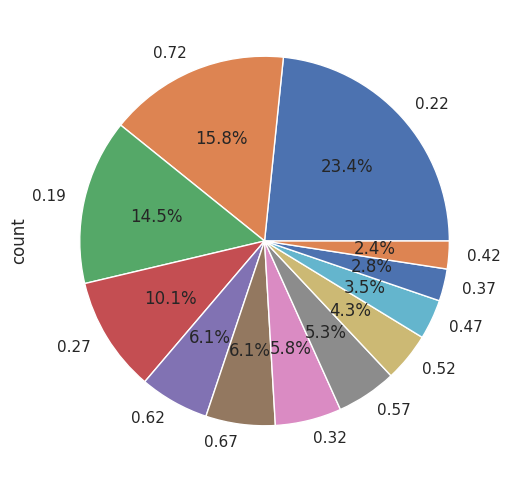

In [ ]:
df['age'].value_counts().plot(kind='pie',autopct='%1.1f%%',figsize=(6,6))

/tmp/ipykernel_1876/3170381030.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], x='visits', data=df, palette='viridis')
/tmp/ipykernel_1876/3170381030.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(ax=axes[1], x='gender', y='visits', data=df, palette='muted', ci=None)
/tmp/ipykernel_1876/3170381030.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x='gender', y='visits', data=df, palette='muted', ci=None)


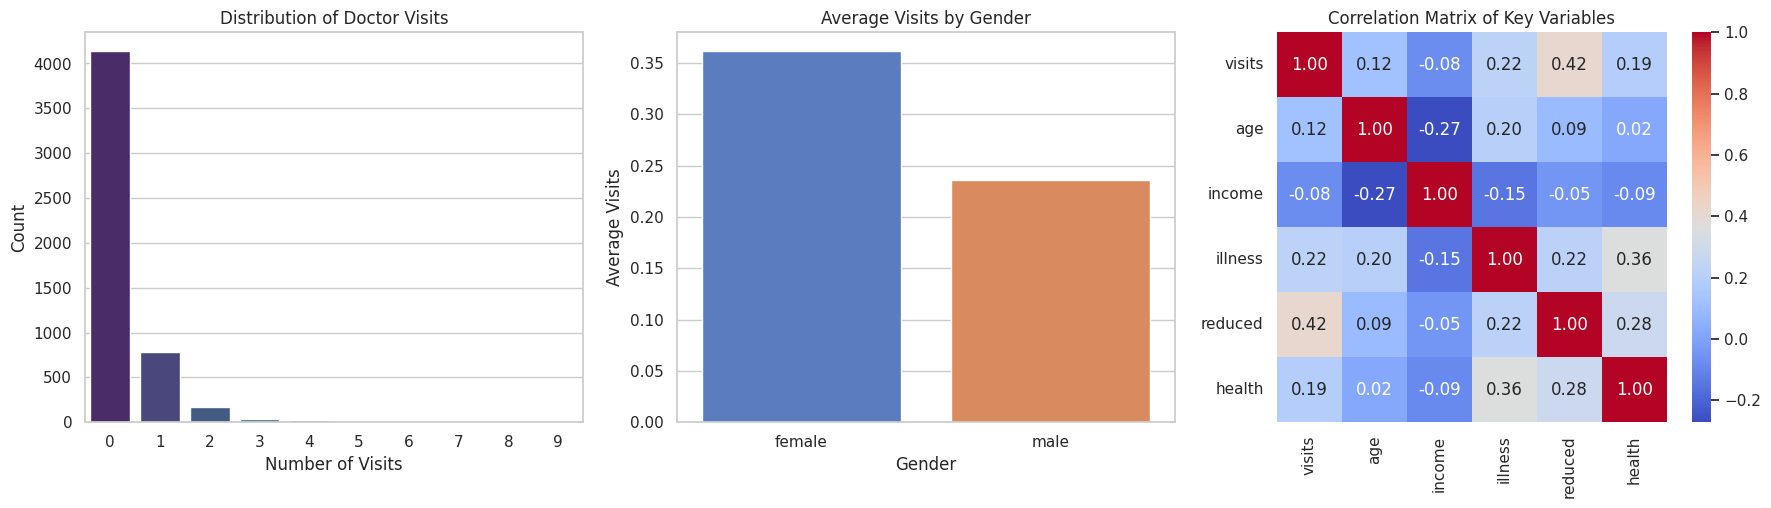

In [ ]:
sns.set_theme(style='whitegrid')
# Create a multi-plot visualization figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of Doctor Visits
sns.countplot(ax=axes[0], x='visits', data=df, palette='viridis')
axes[0].set_title('Distribution of Doctor Visits')
axes[0].set_xlabel('Number of Visits')
axes[0].set_ylabel('Count')

# 2. Average Doctor Visits by Gender
sns.barplot(ax=axes[1], x='gender', y='visits', data=df, palette='muted', ci=None)
axes[1].set_title('Average Visits by Gender')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Average Visits')

# 3. Correlation Heatmap of Numerical Features
numerical_cols = ['visits', 'age', 'income', 'illness', 'reduced', 'health']
corr_matrix = df[numerical_cols].corr()
sns.heatmap(ax=axes[2], data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True)
axes[2].set_title('Correlation Matrix of Key Variables')

plt.tight_layout()
plt.show()

/tmp/ipykernel_1876/2608885228.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['visits'])


<Axes: xlabel='visits', ylabel='Density'>

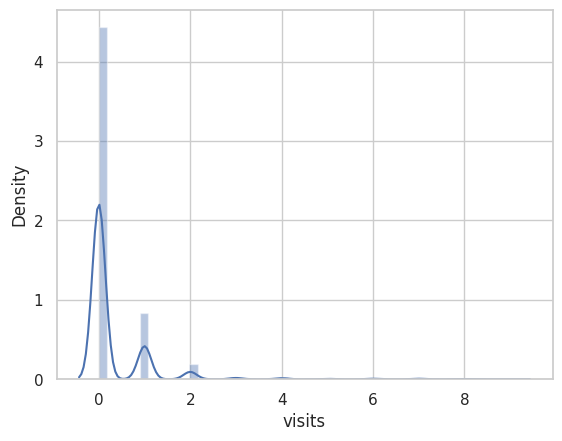

In [ ]:
sns.distplot(df['visits'])

In [ ]:
df['illness'].value_counts()

,count
illness,
1,1638
0,1554
2,946
3,542
4,274
5,236


In [ ]:
df['visits'].value_counts()

,count
visits,
0,4141
1,782
2,174
3,30
4,24
7,12
6,12
5,9
8,5


In [ ]:
df2=df['visits']==0

In [ ]:
df2.value_counts()

,count
visits,
True,4141
False,1049


By the above code it verifies 0 count is actually 4141 in numbers available in data and also verifies in above graph

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Record_id  5190 non-null   int64  
 1   visits     5190 non-null   int64  
 2   gender     5190 non-null   object 
 3   age        5190 non-null   float64
 4   income     5190 non-null   float64
 5   illness    5190 non-null   int64  
 6   reduced    5190 non-null   int64  
 7   health     5190 non-null   int64  
 8   private    5190 non-null   object 
 9   freepoor   5190 non-null   object 
 10  freerepat  5190 non-null   object 
 11  nchronic   5190 non-null   object 
 12  lchronic   5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [ ]:
np.zeros

<function numpy.zeros>

In [ ]:
np.random.randint(0,20,2)

array([19,  6])

In [ ]:
np.unique(df['visits'])

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

Data points count: 5190


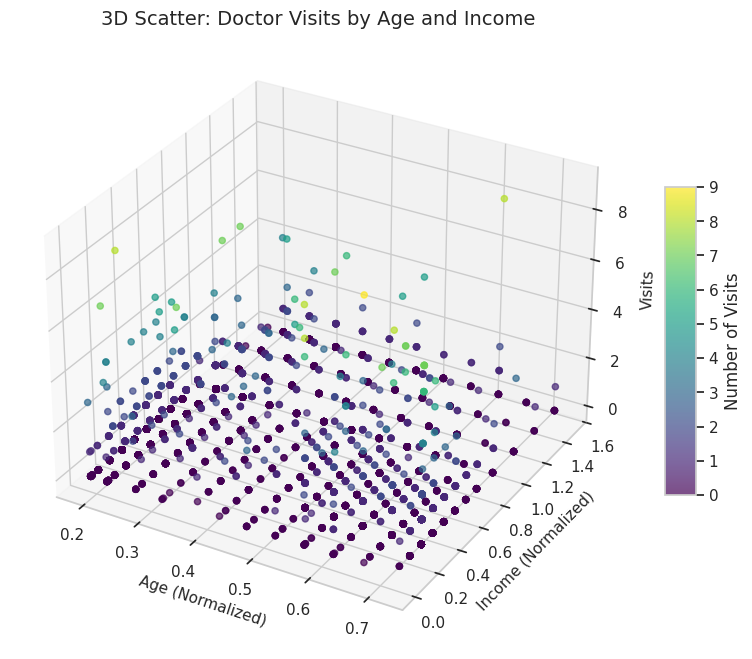

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# Prepare 3 data arrays for the 3 axes
x_data = np.array(df['age'])
y_data = np.array(df['income'])
z_data = np.array(df['visits'])

print(f"Data points count: {len(x_data)}")

# Configure the 3D figure and axes
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Generate a correct 3D scatter plot colored by visits
scatter = ax.scatter(x_data, y_data, z_data, c=z_data, cmap='viridis', alpha=0.7)

# Set labels and title
ax.set_title('3D Scatter: Doctor Visits by Age and Income', fontsize=14)
ax.set_xlabel('Age (Normalized)', fontsize=11)
ax.set_ylabel('Income (Normalized)', fontsize=11)
ax.set_zlabel('Visits', fontsize=11)

# Add a colorbar
fig.colorbar(scatter, ax=ax, shrink=0.5, aspect=10, label='Number of Visits')

plt.show()

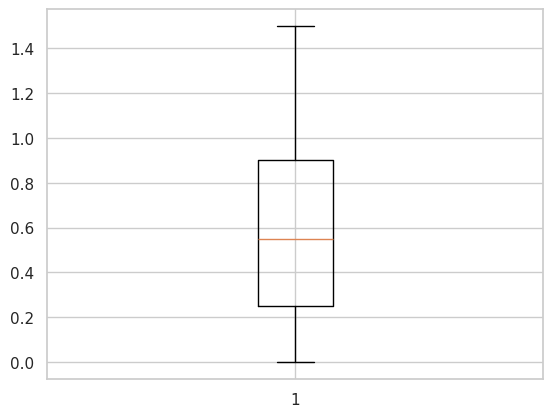

In [ ]:
y=list(df.income)  #vis mean median mode of income of patients
plt.boxplot(y)
plt.show()

In [ ]:
df.groupby(['gender', 'reduced']).mean(numeric_only=True)

Record_id    visits       age    income   illness    health
gender reduced                                                               
female 0        2524.038512  0.229322  0.465755  0.482735  1.462144  1.115098
       1        1985.768421  0.400000  0.325684  0.542105  2.242105  1.610526
       2        1622.618182  0.672727  0.391455  0.560182  2.236364  1.781818
       3         997.311111  1.333333  0.403111  0.516000  2.733333  1.733333
       4        1237.740741  0.851852  0.458889  0.466667  2.222222  2.074074
       5        1169.055556  1.444444  0.401667  0.614444  2.222222  2.500000
       6        1382.545455  1.363636  0.426364  0.622727  2.363636  1.363636
       7        1034.846154  1.384615  0.436154  0.473462  2.653846  2.230769
       8        1883.090909  1.090909  0.471818  0.404545  2.181818  4.000000
       9        1349.000000  0.500000  0.570000  0.825000  3.000000  1.000000
       10       1099.428571  2.142857  0.512857  0.421429  2.571429  2.000000
       12       1661.000000  2.000000  0.720000  0.250000  3.500000  5.500000
       13        906.000000  4.000000  0.720000  0.300000  4.500000  3.500000
       14       1392.112069  1.543103  0.551724  0.427586  2.534483  4.112069
male   0        3008.911019  0.136007  0.344703  0.694398  1.099585  0.924850
       1        2485.158537  0.304878  0.286220  0.676341  1.743902  1.256098
       2        2007.679245  0.471698  0.343585  0.653019  2.358491  1.547170
       3        1909.068966  0.724138  0.334138  0.741379  2.137931  1.689655
       4        1424.000000  0.722222  0.309444  0.869444  2.055556  2.000000
       5        1437.272727  1.136364  0.331818  0.570455  2.272727  2.818182
       6         562.000000  0.833333  0.340000  0.591667  2.500000  2.000000
       7        1716.750000  0.750000  0.314167  0.655000  2.583333  4.333333
       8         680.666667  1.333333  0.365000  0.833333  2.666667  2.000000
       9        1375.400000  2.200000  0.310000  0.392000  2.400000  2.000000
       10       1543.200000  1.800000  0.480000  0.590000  2.600000  4.600000
       11        355.500000  5.000000  0.320000  1.000000  1.500000  0.500000
       12        781.500000  2.000000  0.370000  0.515000  1.500000  1.000000
       13        508.666667  4.000000  0.510000  0.350000  3.333333  2.333333
       14       1236.069444  1.555556  0.476806  0.598611  2.375000  3.527778

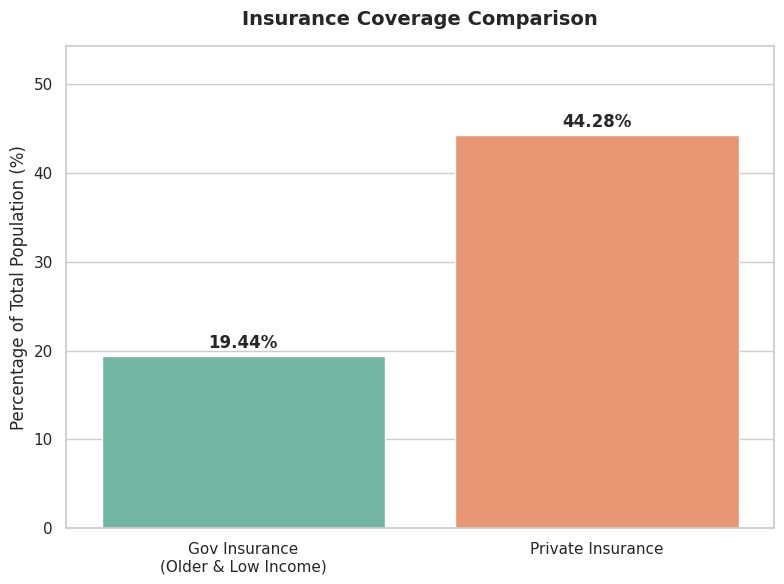

In [ ]:
# Define thresholds based on median values of the normalized data
median_age = df['age'].median()
median_income = df['income'].median()
# Group 1: Government Insurance (freepoor or freerepat), older, and low income
gov_condition = (
    ((df['freepoor'] == 'yes') | (df['freerepat'] == 'yes')) &
    (df['age'] > median_age) &
    (df['income'] < median_income))
# Group 2: Private Insurance users
private_condition = (df['private'] == 'yes')
# Calculate percentages
total_people = len(df)
pct_gov_old_low_income = (gov_condition.sum() / total_people) * 100
pct_private = (private_condition.sum() / total_people) * 100
# Data for plotting
categories = [
    'Gov Insurance\n(Older & Low Income)',
    'Private Insurance']
percentages = [pct_gov_old_low_income, pct_private]
# Plotting the comparison
plt.figure(figsize=(8, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(x=categories, y=percentages, hue=categories, palette='Set2', legend=False)
# Annotate bars with percentage values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=12, fontweight='bold')
plt.title('Insurance Coverage Comparison', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Percentage of Total Population (%)', fontsize=12)
plt.ylim(0, max(percentages) + 10)
plt.tight_layout()
plt.show()

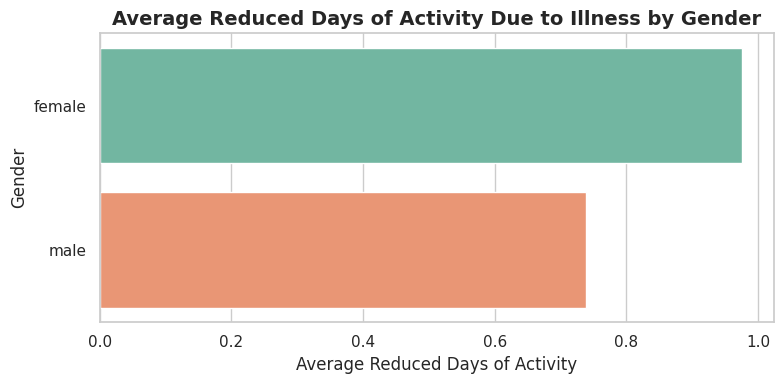

In [ ]:
#Average Reduced Days of Activity Due to Illness by Gender
plt.figure(figsize=(8, 4))
sns.barplot(x='reduced', y='gender', data=df, errorbar=None, palette='Set2', hue='gender', legend=False)
plt.title('Average Reduced Days of Activity Due to Illness by Gender', fontsize=14, fontweight='bold')
plt.xlabel('Average Reduced Days of Activity', fontsize=12)
plt.ylabel('Gender', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
!pip install ydata-profiling


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 67.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.6 MB/s eta 0:00:00


In [ ]:
from pandas_profiling import ProfileReport
profile=ProfileReport(df,title='Pandas Profiling Report',explorative=True)
profile.to_file('Output.html')

/tmp/ipykernel_1876/798062436.py:1: DeprecationWarning: `import pandas_profiling` is going to be deprecated by April 1st. Please use `import ydata_profiling` instead.
  from pandas_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 38.55it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]